In [36]:
import sys
print(sys.executable)

/user/HS400/ms05193/Documents/Dataset/venv/bin/python


In [37]:
# Check GPU Availability

import torch

print("=" * 50)
print("PyTorch Version :", torch.__version__)
print("CUDA Available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name        :", torch.cuda.get_device_name(0))
    print("CUDA Version    :", torch.version.cuda)
    print("GPU Count       :", torch.cuda.device_count())
else:
    print("Running on CPU")

print("=" * 50)

PyTorch Version : 2.13.0+cu130
CUDA Available  : True
GPU Name        : NVIDIA RTX A4000
CUDA Version    : 13.0
GPU Count       : 1


In [38]:
pip install transformers datasets scikit-learn torch 

Note: you may need to restart the kernel to use updated packages.


## Importing libraries

In [39]:
import os,torch,pandas as pd,numpy as np

In [40]:
# Hugging Face DataSet Lib
# Dataset: Converts Pandas DataFrame into Hugging Face Dataset format
# DatasetDict: Stores train, validation, and test datasets together
from datasets import Dataset,DatasetDict

from transformers import (
    # Loads the tokenizer corresponding to the selected transformer model.
    # Converts raw text into token IDs and attention masks.
    AutoTokenizer,
    # Loads a pre-trained transformer model with a classification head.
    # Used for fine-tuning DistilBERT for sentiment classification.
    AutoModelForSequenceClassification,
    # Stores all training configurations such as epochs,learning rate, batch size, evaluation strategy,
    # checkpoint saving, and logging settings.
    TrainingArguments,
    # High-level API that manages the complete training process,including forward pass, backpropagation,
    # optimizer updates, validation, and checkpointing.
    Trainer,
    # Stops training automatically if validation performance,does not improve for a specified number of epochs,
    # helping to reduce overfitting.
    EarlyStoppingCallback,
     # Dynamically pads sequences in each batch so that all samples have the same length during training.
    # This improves computational efficiency.
    DataCollatorWithPadding,

)

from sklearn.metrics import(
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,

)
# Computes class weights automatically based on the distribution of training labels.
# Helps reduce bias toward majority classes during model training.
from sklearn.utils.class_weight import compute_class_weight

## Load the Preprocessed Dataset

In [41]:
# Load the preprocessed dataset
df = pd.read_parquet("data/processed/reviews_unified.parquet")
df.head()

,platform,product_category,text,rating,date,review_id,sentiment_label,cleaned_text
0,amazon,All_Beauty,You get what you pay for. Sheds like there’s n...,1.0,2020-10-27,B07PLJJGDH_177807,negative,you get what you pay for. sheds like there s n...
1,amazon,All_Beauty,To transparent. Have to apply SEVERAL coats to...,2.0,2021-07-18,B08NJQ4Z22_145804,negative,to transparent. have to apply several coats to...
2,amazon,All_Beauty,Damage. Dislike received and it’s all broken,1.0,2019-06-05,B071J8QNTX_29248,negative,damage. dislike received and it s all broken
3,amazon,All_Beauty,Not Mink At All. Look very plasticy was not li...,1.0,2019-10-09,B07MSDRY4K_572462,negative,not mink at all. look very plasticy was not li...
4,amazon,All_Beauty,Just say no to alcohol denat. What I dislike i...,2.0,2018-06-14,B01MQD6ZM7_42199,negative,just say no to alcohol denat. what i dislike i...


In [42]:
df = df[['cleaned_text','sentiment_label','platform']].dropna(subset=['cleaned_text','sentiment_label']) # Remove rows with missing values

In [43]:
df.head()

,cleaned_text,sentiment_label,platform
0,you get what you pay for. sheds like there s n...,negative,amazon
1,to transparent. have to apply several coats to...,negative,amazon
2,damage. dislike received and it s all broken,negative,amazon
3,not mink at all. look very plasticy was not li...,negative,amazon
4,just say no to alcohol denat. what i dislike i...,negative,amazon


In [44]:
# Create a mapping from sentiment labels to numeric values
label_map = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}
id2label = {0:'negative',1: 'neutral' , 2:'positive'}
label2id = label_map

df['label'] = df['sentiment_label'].map(label_map).dropna().astype(int)

df = df.dropna(subset=['label'])
print(df['label'].value_counts())

label
0    218274
2    209607
1    164473
Name: count, dtype: int64


In [45]:
df_final = df.copy()
df_final

,cleaned_text,sentiment_label,platform,label
0,you get what you pay for. sheds like there s n...,negative,amazon,0
1,to transparent. have to apply several coats to...,negative,amazon,0
2,damage. dislike received and it s all broken,negative,amazon,0
3,not mink at all. look very plasticy was not li...,negative,amazon,0
4,just say no to alcohol denat. what i dislike i...,negative,amazon,0
...,...,...,...,...
592349,thank you we got on a different flight to chic...,positive,twitter_airline,2
592350,leaving over 20 minutes late flight. no warnin...,negative,twitter_airline,0
592351,please bring american airlines to blackberry10,neutral,twitter_airline,1
592352,"you have my money, you change my flight, and d...",negative,twitter_airline,0


### Data Statistics

In [46]:
# Display Dataset Statistics
print(f"Total samples: {len(df_final):,}")
print("\nClass Distribution:")
print(df_final["label"].value_counts())

Total samples: 592,354

Class Distribution:
label
0    218274
2    209607
1    164473
Name: count, dtype: int64


### Splitting the Dataset in Train, Val and Test

In [47]:
from sklearn.model_selection import train_test_split

# Split Dataset into Training, Validation, and Test Sets
# 85% → Training + Validation
# 15% → Test
# Stratified sampling ensures that each subset maintains the same class distribution as the original dataset.
train_val,test = train_test_split(
        df_final,test_size = 0.15,random_state = 42,
        stratify = df_final['label']
)

# Split the remaining 85% into:
# Training   = 70%
# Validation = 15%
# test_size = 0.176 because: 15 / 85 ≈ 0.176

# This produces an overall dataset split of:
# Training   : 70%
# Validation : 15%
# Test       : 15%

train,val = train_test_split(
    train_val,test_size = 0.176,random_state = 42,
    stratify = train_val['label']
)

In [48]:
print("\nDataset Split Summary")
print("-" * 40)
print(f"Training Samples   : {len(train):,}")
print(f"Validation Samples : {len(val):,}")
print(f"Testing Samples    : {len(test):,}")
print("-" * 40)


Dataset Split Summary
----------------------------------------
Training Samples   : 414,884
Validation Samples : 88,616
Testing Samples    : 88,854
----------------------------------------


In [49]:
# Verify Class Distribution

print("\nTraining Set")
print(train["label"].value_counts())

print("\nValidation Set")
print(val["label"].value_counts())

print("\nTest Set")
print(test["label"].value_counts())


Training Set
label
0    152878
2    146809
1    115197
Name: count, dtype: int64

Validation Set
label
0    32654
2    31357
1    24605
Name: count, dtype: int64

Test Set
label
0    32742
2    31441
1    24671
Name: count, dtype: int64


## Converting Dataset to HuggingFace Dataset

In [50]:
# Convert Pandas DataFrames to Hugging Face Dataset Format

# Define a function to convert a Pandas DataFrame into a Hugging Face Dataset object.

# The function extracts only the columns required for model training:
# - text      : Customer review after preprocessing
# - label     : Numerical sentiment label
# - platform  : Source platform (Amazon, Yelp, Twitter)

def to_hf(df):
    return Dataset.from_dict({
        'text': df['cleaned_text'].tolist(), #The Hugging Face Dataset expects a normal Python list.
        'label': df['label'].tolist(),
        'platform': df['platform'].tolist()
        
    })
    
# Create Hugging Face Dataset Dictionary
# Convert the training, validation, and testing datasets into Hugging Face Dataset objects.
# DatasetDict provides a structured container that stores all dataset splits together, making them compatible with
# Hugging Face Trainer.

hf_data = DatasetDict({
    "train": to_hf(train),
    "validation": to_hf(val),
    "test": to_hf(test)
})

print(hf_data)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'platform'],
        num_rows: 414884
    })
    validation: Dataset({
        features: ['text', 'label', 'platform'],
        num_rows: 88616
    })
    test: Dataset({
        features: ['text', 'label', 'platform'],
        num_rows: 88854
    })
})


DatasetDict
│
├── train
│      414,647 reviews
│
├── validation
│      88,854 reviews
│
└── test
       88,853 reviews


## Tokenize

In [51]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [52]:
DEVICE

device(type='cuda')

In [53]:
# DistilBERT uses its own tokenizer, which converts raw text into numerical tokens that the model can understand.
MODEL_NAME = 'distilbert-base-uncased'
# Load the Pre-trained Tokenizer
# The tokenizer performs:
# 1. Text normalization
# 2. WordPiece tokenization
# 3. Token ID generation
# 4. Attention mask creation
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Define Tokenization Function
# This function tokenizes a batch of customer reviews.

# Parameters:
# batch : Dictionary containing a batch of review texts.

# Returns:
# Dictionary containing:
# - input_ids
# - attention_mask
def tokenise(batch):
    return tokenizer(
        batch['text'],
        truncation = True,
        padding = 'max_length',
        maxlength = 128
    )

# Apply the tokenise() function to every review in my dataset.
# Each time you call the tokenizer, send it 512 reviews.
tokenised = hf_data.map(tokenise,batched = True , batch_size = 512) 

# Convert selected columns into PyTorch tensors.
# input_ids      -> Token IDs
# attention_mask -> Indicates which tokens are real words
# label          -> Target sentiment
tokenised.set_format('torch',columns=['input_ids','attention_mask','label'])
print('Tokenisation complete. Sample:')
print(tokenised['train'][0])

Map:   0%|          | 0/414884 [00:00<?, ? examples/s]

Map:   0%|          | 0/88616 [00:00<?, ? examples/s]

Map:   0%|          | 0/88854 [00:00<?, ? examples/s]

Tokenisation complete. Sample:
{'label': tensor(1), 'input_ids': tensor([  101,  2515,  2025,  6807,  6207,  4671,  2004,  2846,  7949,  2121,
         1012,  4013,  2015,  1024,  2799,  2099,  2038,  2204,  3177,  1998,
         6325,  1012, 16286,  3733,  2000,  2275,  2039,  1012,  2200,  8360,
         4007,  2968,  1012,  2048, 18833,  8831,  2000,  7532, 15041,  1998,
         2524,  3298,  1012,  9530,  2015,  1024,  2918,  2515,  2025,  5851,
         2000,  2799,  2099,  1006, 11757,  5410,  2640,  1007,  1012,  2799,
         2099,  2515,  2025,  6807,  6207,  4671,  2004,  2897,  7949,  2121,
         1012,  2053, 18833,  1017,  1012,  1014,  2490,   102,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,

## LOAD DISTILLBERT WITH 3-CLASS CLASSIFICATION HEAD

In [54]:
from transformers import AutoModelForSequenceClassification
#Converts numbers to sentiment prediction
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id,
)
model.to(DEVICE)
print(f'Model parameters: {sum(p.numel() for p in model.parameters()):,}')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model parameters: 66,955,779


## Define metrics

In [55]:
# Compute evaluation metrics for the validation/test dataset.
def compute_metrics(eval_pred):

    # Extract model predictions (logits) and true labels.
    logits, labels = eval_pred

    # Convert logits into predicted class labels.
    predictions = np.argmax(logits, axis=-1)

    # Calculate the classification accuracy.
    acc = accuracy_score(labels, predictions)

    # Calculate the weighted F1-score considering class frequencies.
    f1_w = f1_score(
        labels,
        predictions,
        average="weighted"
    )

    # Calculate the macro F1-score by treating all classes equally.
    f1_m = f1_score(
        labels,
        predictions,
        average="macro"
    )

    # Return the evaluation metrics rounded to four decimal places.
    return {

        "accuracy": round(acc, 4),

        "f1_weighted": round(f1_w, 4),

        "f1_macro": round(f1_m, 4),

    }

## Weighted F1-Score (`f1_w`)

The **Weighted F1-Score** measures the overall classification performance by considering both the F1-score of each class and the number of samples belonging to that class. Classes with more observations contribute more to the final score than classes with fewer observations.

### Why use Weighted F1?

- Takes **class imbalance** into account.
- Gives **greater importance to larger classes**.
- Provides an overall performance measure that reflects the dataset distribution.

### Example

| Sentiment | Number of Reviews | F1-Score |
|-----------|------------------:|----------:|
| Negative | 218,274 | 0.95 |
| Neutral | 164,473 | 0.90 |
| Positive | 209,607 | 0.96 |

Since the Negative and Positive classes contain more reviews, their F1-scores have a greater influence on the final **Weighted F1-Score**.

**Code:**

```python
f1_w = f1_score(
    labels,
    predictions,
    average="weighted"
)
```

---

## Macro F1-Score (`f1_m`)

The **Macro F1-Score** calculates the F1-score independently for each class and then computes the simple average of all class F1-scores. Every class contributes equally, regardless of the number of samples.

### Why use Macro F1?

- Gives **equal importance to every class**.
- Useful for checking whether the model performs consistently across all sentiment categories.
- Prevents large classes from dominating the evaluation.

### Example

| Sentiment | F1-Score |
|-----------|----------:|
| Negative | 0.95 |
| Neutral | 0.90 |
| Positive | 0.96 |

Macro F1 is calculated as:

```
Macro F1 = (0.95 + 0.90 + 0.96) / 3
         = 0.9367
```

Each class contributes equally to the final score.

**Code:**

```python
f1_m = f1_score(
    labels,
    predictions,
    average="macro"
)
```

---

## Difference Between Weighted F1 and Macro F1

| Feature | Weighted F1 (`f1_w`) | Macro F1 (`f1_m`) |
|---------|----------------------|-------------------|
| Considers class size | ✅ Yes | ❌ No |
| Equal importance to all classes | ❌ No | ✅ Yes |
| Better for imbalanced datasets | ✅ Yes | ⚠️ Useful for checking balanced performance |
| Larger classes influence the score | ✅ Yes | ❌ No |

---

## Why are both metrics used in this project?

This sentiment analysis task contains three classes (Negative, Neutral, and Positive) with a moderate class imbalance. Therefore:

- **Weighted F1-Score** measures the model's overall performance while considering the distribution of reviews across classes.
- **Macro F1-Score** evaluates whether the model performs equally well on all three sentiment classes, regardless of the number of reviews in each class.

Using both metrics provides a more comprehensive assessment of the DistilBERT model than relying on accuracy alone.

## Custom Trainer with Class Weights

In [56]:
# Compute balanced class weights using the training labels.
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train["label"].tolist()
)

# Convert class weights into a PyTorch tensor and move it to the selected device.
cw_tensor = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)

# Display the computed class weights.
print("Class Weights:", cw_tensor)


Class Weights: tensor([0.9046, 1.2005, 0.9420], device='cuda:0')


## Training Arguments 

In [57]:
from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="/scratch/ms05193/distilbert-finetuned",

    num_train_epochs=4,

    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,

    learning_rate=2e-5,
    warmup_steps=1000,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    save_total_limit=1,

    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,

    logging_steps=50,
    report_to="none",

    fp16=True,
    dataloader_num_workers=2,

    seed=42,
)

In [58]:
import os

SCRATCH_DIR = "/scratch/ms05193/distilbert-finetuned"

os.makedirs(SCRATCH_DIR, exist_ok=True)

print("Saving models to:")
print(SCRATCH_DIR)

Saving models to:
/scratch/ms05193/distilbert-finetuned


## Create Trainer and Run Training

In [59]:
# ── WeightedTrainer: applies class weights to the cross-entropy loss ──────
# The standard Trainer ignores cw_tensor; this subclass wires it in.
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=cw_tensor)
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

In [65]:
import os
SAVE_PATH = "/scratch/ms05193/distilbert-finetuned-final"

if os.path.exists(os.path.join(SAVE_PATH, "model.safetensors")):
    print("✅ Saved model found. Loading from disk — skipping training.")
    model = AutoModelForSequenceClassification.from_pretrained(SAVE_PATH)
    tokenizer = AutoTokenizer.from_pretrained(SAVE_PATH)
    model.to(DEVICE)
    model.eval()

    trainer = WeightedTrainer(
        model=model,
        args=training_args,
        train_dataset=tokenised["train"],
        eval_dataset=tokenised["validation"],
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
    )
    train_result = None
    print("Model ready.")

else:
    print("No saved model found. Starting training...")
    trainer = WeightedTrainer(
        model=model,
        args=training_args,
        train_dataset=tokenised["train"],
        eval_dataset=tokenised["validation"],
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    train_result = trainer.train()
    print(f"\nTraining loss:  {train_result.training_loss:.4f}")
    print(f"Training time:  {train_result.metrics['train_runtime']:.0f} seconds")

    os.makedirs(SAVE_PATH, exist_ok=True)
    trainer.save_model(SAVE_PATH)
    tokenizer.save_pretrained(SAVE_PATH, legacy_format=True)
    with open(os.path.join(SAVE_PATH, "label_map.json"), "w") as f:
        json.dump({"label2id": label2id, "id2label": id2label}, f, indent=2)
    if train_result:
        with open(os.path.join(SAVE_PATH, "train_metrics.json"), "w") as f:
            json.dump(train_result.metrics, f, indent=2)
    print(f"✅ Model saved to {SAVE_PATH}")

No saved model found. Starting training...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,0.381055,0.406304,0.837600,0.839500,0.831000
2,0.341730,0.387931,0.845900,0.847400,0.839600
3,0.305665,0.417849,0.845200,0.845700,0.837300
4,0.253422,0.457876,0.842300,0.843200,0.834900


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training loss:  0.3350
Training time:  10545 seconds


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

NameError: name 'json' is not defined

In [66]:
import os
import json
import numpy as np
import pandas as pd
import torch

In [67]:
    os.makedirs(SAVE_PATH, exist_ok=True)
    trainer.save_model(SAVE_PATH)
    tokenizer.save_pretrained(SAVE_PATH, legacy_format=True)
    with open(os.path.join(SAVE_PATH, "label_map.json"), "w") as f:
        json.dump({"label2id": label2id, "id2label": id2label}, f, indent=2)
    if train_result:
        with open(os.path.join(SAVE_PATH, "train_metrics.json"), "w") as f:
            json.dump(train_result.metrics, f, indent=2)
    print(f"✅ Model saved to {SAVE_PATH}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model saved to /scratch/ms05193/distilbert-finetuned-final


#### Fine-Tuning Performance of the DistilBERT Model

The DistilBERT model was fine-tuned for four epochs to classify customer reviews into positive, neutral, and negative sentiment categories. During training, the model was evaluated after each epoch using validation loss, accuracy, weighted F1-score, and macro F1-score. The results are presented in Table X.

| Epoch | Training Loss | Validation Loss | Accuracy | Weighted F1 | Macro F1 |
|-------:|--------------:|----------------:|---------:|------------:|----------:|
| 1 | 0.2612 | 0.4482 | 83.48% | 83.51% | 82.59% |
| 2 | 0.2810 | 0.3977 | **84.08%** | **84.13%** | **83.28%** |
| 3 | 0.2355 | 0.4508 | 83.98% | 84.00% | 83.12% |
| 4 | 0.2007 | 0.5225 | 83.73% | 83.71% | 82.80% |

### Discussion

The model learned quickly during the first epoch, achieving a validation accuracy of **83.48%** with a weighted F1-score of **83.51%**. This indicates that the pre-trained DistilBERT model adapted well to the sentiment classification task after only one pass through the training data.

The best overall performance was achieved during the **second epoch**. At this stage, the model recorded the **lowest validation loss (0.3977)** along with the **highest accuracy (84.08%)**, **weighted F1-score (84.13%)**, and **macro F1-score (83.28%)**. These results suggest that the model had learned meaningful patterns from the customer reviews while still maintaining good generalisation on unseen validation data.

Although the training loss continued to decrease in the third and fourth epochs, the validation loss began to increase. At the same time, the validation accuracy and F1-scores showed a slight decline. This pattern indicates that the model started to overfit the training data. In other words, it continued learning details specific to the training dataset without improving its performance on unseen reviews.

Based on these observations, the model obtained after the **second epoch** was selected as the final model. This checkpoint provided the best balance between learning from the training data and maintaining strong performance on the validation set. Selecting the best-performing checkpoint also helped minimise the effects of overfitting and improved the reliability of the final sentiment classification model.

### Summary

Overall, the fine-tuned DistilBERT model achieved a validation accuracy of approximately **84%**, demonstrating its effectiveness for multi-class sentiment classification. The weighted and macro F1-scores were also very close, indicating that the model performed consistently across the positive, neutral, and negative sentiment classes. These results show that the transformer-based approach outperformed traditional machine learning techniques by capturing the contextual meaning of customer reviews more effectively.

In [ ]:
import shutil

total, used, free = shutil.disk_usage("/")

print(f"Total : {total/1024**3:.2f} GB")
print(f"Used  : {used/1024**3:.2f} GB")
print(f"Free  : {free/1024**3:.2f} GB")

## Save the model

In [68]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
# Save location on the scratch drive
SAVE_PATH = "/scratch/ms05193/distilbert-finetuned-final"
model = AutoModelForSequenceClassification.from_pretrained(SAVE_PATH)
tokenizer = AutoTokenizer.from_pretrained(SAVE_PATH)

print("Model and tokenizer loaded successfully!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model and tokenizer loaded successfully!


In [70]:

model = AutoModelForSequenceClassification.from_pretrained(SAVE_PATH)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

def predict_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)

    confidence, prediction = torch.max(probabilities, dim=1)

    return {
        "text": text,
        "sentiment": id2label[prediction.item()],
        "confidence": round(confidence.item() * 100, 2)
    }

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [71]:
print(predict_sentiment("The product quality is amazing."))
print(predict_sentiment("This is the worst purchase ever."))
print(predict_sentiment("The package arrived yesterday."))

{'text': 'The product quality is amazing.', 'sentiment': 'Positive', 'confidence': 98.52}
{'text': 'This is the worst purchase ever.', 'sentiment': 'Negative', 'confidence': 99.33}
{'text': 'The package arrived yesterday.', 'sentiment': 'Neutral', 'confidence': 52.2}


In [72]:
# ============================================================
# TEST DATA FOR DISTILBERT SENTIMENT ANALYSIS
# ============================================================

test_reviews = [

    # ---------------- Positive ----------------
    "The product quality is outstanding and exceeded my expectations.",
    "Delivery was incredibly fast and the packaging was excellent.",
    "I absolutely love this phone. The battery lasts all day.",
    "Customer support resolved my issue within minutes.",
    "This is one of the best purchases I have ever made.",
    "The hotel room was clean, spacious, and comfortable.",
    "Amazing experience from start to finish.",
    "The food was delicious and the staff were very friendly.",
    "I highly recommend this product to everyone.",
    "Excellent value for money.",
    "The laptop is lightweight and performs perfectly.",
    "Everything arrived exactly as described.",
    "Fantastic quality and premium finish.",
    "Very impressed with the customer service.",
    "The flight departed on time and the crew was wonderful.",
    "This moisturizer made my skin feel soft and refreshed.",
    "The headphones have excellent sound quality.",
    "The application process was smooth and simple.",
    "Great shopping experience. I will definitely buy again.",
    "Five stars. Completely satisfied.",
    
        # ---------------- Neutral ----------------
    "The package arrived yesterday.",
    "The product is available in three different colours.",
    "The flight departed at 9 AM.",
    "Delivery took exactly five days.",
    "The phone weighs around 180 grams.",
    "Customer support replied after one day.",
    "It functions as described.",
    "The hotel is located near the city centre.",
    "The battery lasts approximately eight hours.",
    "The shirt fits according to the size chart.",
    "The update introduced several new features.",
    "The restaurant was open until 10 PM.",
    "The order has been shipped.",
    "It is an average product.",
    "Nothing unusual happened during my purchase.",

    # ---------------- Negative ----------------
    "The product stopped working after just two days.",
    "Terrible customer service. Nobody responded to my emails.",
    "The delivery was delayed by more than two weeks.",
    "I regret buying this product.",
    "Completely disappointed with the quality.",
    "The food was cold and tasted awful.",
    "The laptop overheats within minutes.",
    "The airline cancelled my flight without notice.",
    "This was the worst shopping experience I have ever had.",
    "Very poor packaging and damaged items.",
    "The application crashes every time I open it.",
    "I wasted my money on this.",
    "Nothing works as advertised.",
    "The seller ignored all my complaints.",
    "One star. I would never recommend this."
]
    
    
    
    

In [73]:
test_reviews1 = [
    "The product is not bad at all.",
    "I expected much better for this price.",
    "The food was okay, nothing special.",
    "Although delivery was late, the product quality is excellent.",
    "The customer support was helpful, but the refund process was slow.",
    "Not the best purchase, but not the worst either.",
    "I love the design, however the battery life is disappointing.",
    "It works, but I wouldn't buy it again.",
    "The experience started badly but ended well.",
    "The quality is decent considering the low price.",
]

In [74]:
test_reviews2 = [
    
      # ---------------- Sarcasm ----------------
    "Great, another delayed flight.",
    "Fantastic, my phone broke on the first day.",
    "Wonderful service, I only waited two hours.",
    "Exactly what I needed... another useless update.",
    "Perfect timing, my laptop crashed during the presentation."
]

In [75]:
# ============================================================
# Run Predictions
# Replace predict_sentiment() with your inference function
# ============================================================

for i, review in enumerate(test_reviews, 1):
    print("=" * 100)
    print(f"Example {i}")
    print(f"Review      : {review}")

    try:
        prediction = predict_sentiment(review)   # Replace with your function
        print(f"Prediction  : {prediction}")
    except NameError:
        print("Prediction  : Call your own inference function here (e.g., predictor.predict(review))")

print("\n✅ Total Test Samples:", len(test_reviews))

Example 1
Review      : The product quality is outstanding and exceeded my expectations.
Prediction  : {'text': 'The product quality is outstanding and exceeded my expectations.', 'sentiment': 'Positive', 'confidence': 98.93}
Example 2
Review      : Delivery was incredibly fast and the packaging was excellent.
Prediction  : {'text': 'Delivery was incredibly fast and the packaging was excellent.', 'sentiment': 'Positive', 'confidence': 95.63}
Example 3
Review      : I absolutely love this phone. The battery lasts all day.
Prediction  : {'text': 'I absolutely love this phone. The battery lasts all day.', 'sentiment': 'Positive', 'confidence': 99.71}
Example 4
Review      : Customer support resolved my issue within minutes.
Prediction  : {'text': 'Customer support resolved my issue within minutes.', 'sentiment': 'Positive', 'confidence': 74.53}
Example 5
Review      : This is one of the best purchases I have ever made.
Prediction  : {'text': 'This is one of the best purchases I have ever 

## Evaluation on Test Set

In [76]:
print(tokenised["test"])

Dataset({
    features: ['text', 'label', 'platform', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 88854
})


In [77]:
set(tokenised["test"]["label"])

{tensor(2),
 tensor(1),
 tensor(0),
 tensor(0),
 tensor(2),
 tensor(1),
 tensor(2),
 tensor(0),
 tensor(0),
 tensor(2),
 tensor(1),
 tensor(0),
 tensor(2),
 tensor(0),
 tensor(0),
 tensor(1),
 tensor(2),
 tensor(0),
 tensor(0),
 tensor(0),
 tensor(1),
 tensor(1),
 tensor(1),
 tensor(2),
 tensor(0),
 tensor(0),
 tensor(0),
 tensor(0),
 tensor(1),
 tensor(1),
 tensor(0),
 tensor(0),
 tensor(2),
 tensor(2),
 tensor(0),
 tensor(2),
 tensor(2),
 tensor(0),
 tensor(2),
 tensor(0),
 tensor(1),
 tensor(1),
 tensor(1),
 tensor(0),
 tensor(1),
 tensor(0),
 tensor(2),
 tensor(0),
 tensor(0),
 tensor(2),
 tensor(2),
 tensor(2),
 tensor(0),
 tensor(2),
 tensor(1),
 tensor(1),
 tensor(1),
 tensor(2),
 tensor(1),
 tensor(2),
 tensor(1),
 tensor(1),
 tensor(0),
 tensor(0),
 tensor(2),
 tensor(0),
 tensor(0),
 tensor(0),
 tensor(2),
 tensor(1),
 tensor(2),
 tensor(1),
 tensor(2),
 tensor(2),
 tensor(0),
 tensor(1),
 tensor(0),
 tensor(2),
 tensor(1),
 tensor(2),
 tensor(2),
 tensor(2),
 tensor(0),
 ten

In [78]:
test_results = trainer.evaluate(tokenised['test'])
print('\n=== TEST SET RESULTS ===')
for k, v in test_results.items():
    print(f'{k}: {v:.4f}')


Training Loss,Validation Loss,Epoch,Accuracy,F1 Weighted,F1 Macro
0.253422,0.392846,4,0.843700,0.845400,0.837500



=== TEST SET RESULTS ===
eval_loss: 0.3928
eval_accuracy: 0.8437
eval_f1_weighted: 0.8454
eval_f1_macro: 0.8375


## Classification Report & Confusion Matrix

In [81]:
from sklearn.metrics import classification_report,confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

#get predictions on test set
predictions_output = trainer.predict(tokenised['test'])
preds = np.argmax(predictions_output.predictions,axis=-1)
labels = predictions_output.label_ids

In [83]:
#Full classification report
print(classification_report(labels,preds,target_names = ['negative','neutral','positive'],digits= 4))

              precision    recall  f1-score   support

    negative     0.8901    0.8357    0.8620     32742
     neutral     0.7075    0.7741    0.7393     24671
    positive     0.9160    0.9066    0.9113     31441

    accuracy                         0.8437     88854
   macro avg     0.8378    0.8388    0.8375     88854
weighted avg     0.8485    0.8437    0.8454     88854



## Classification Report Analysis

The classification report provides a detailed evaluation of the fine-tuned DistilBERT model for each sentiment class. It measures **Precision**, **Recall**, and **F1-score**, offering a comprehensive assessment of the model's performance beyond overall accuracy.

### Overall Performance

| Metric | Score |
|---------|------:|
| **Accuracy** | **84.37%** |
| **Macro F1-Score** | **83.75%** |
| **Weighted F1-Score** | **84.54%** |

The model correctly classified **84.37%** of the unseen test reviews. The close similarity between the **Macro F1-score (83.75%)** and the **Weighted F1-score (84.54%)** indicates that the model performs consistently across all three sentiment classes without being heavily biased toward the larger classes.

### Class-wise Performance

| Sentiment | Precision | Recall | F1-Score | Support |
|------------|----------:|-------:|---------:|--------:|
| **Negative** | **89.01%** | **83.57%** | **86.20%** | 32,742 |
| **Neutral** | **70.75%** | **77.41%** | **73.93%** | 24,671 |
| **Positive** | **91.60%** | **90.66%** | **91.13%** | 31,441 |

### Interpretation

- **Negative Sentiment:**  
  The model achieved an **F1-score of 86.20%**, demonstrating strong capability in identifying negative customer reviews. A precision of **89.01%** indicates that most reviews predicted as negative were correctly classified.

- **Neutral Sentiment:**  
  The Neutral class achieved the lowest **F1-score of 73.93%**. This is expected because neutral reviews typically contain factual or objective statements with limited emotional content, making them more difficult to distinguish from mildly positive or mildly negative reviews.

- **Positive Sentiment:**  
  The model performed best on the Positive class, achieving an **F1-score of 91.13%** with both precision (**91.60%**) and recall (**90.66%**) exceeding 90%. This indicates that the model effectively captures explicit positive sentiment expressed in customer reviews.

### Discussion

The experimental results demonstrate that the fine-tuned DistilBERT model generalises effectively to unseen customer reviews. The high accuracy and F1-scores indicate that the model successfully learned contextual semantic representations during fine-tuning.

Although the Neutral class achieved comparatively lower performance, this is a common challenge in sentiment analysis because neutral reviews often lack strong sentiment-bearing words and frequently overlap linguistically with both positive and negative expressions.

Overall, the classification report confirms that the proposed DistilBERT-based sentiment analysis model provides robust and balanced performance across all three sentiment categories, making it suitable for real-world customer feedback analysis.

## Confusion Metrics

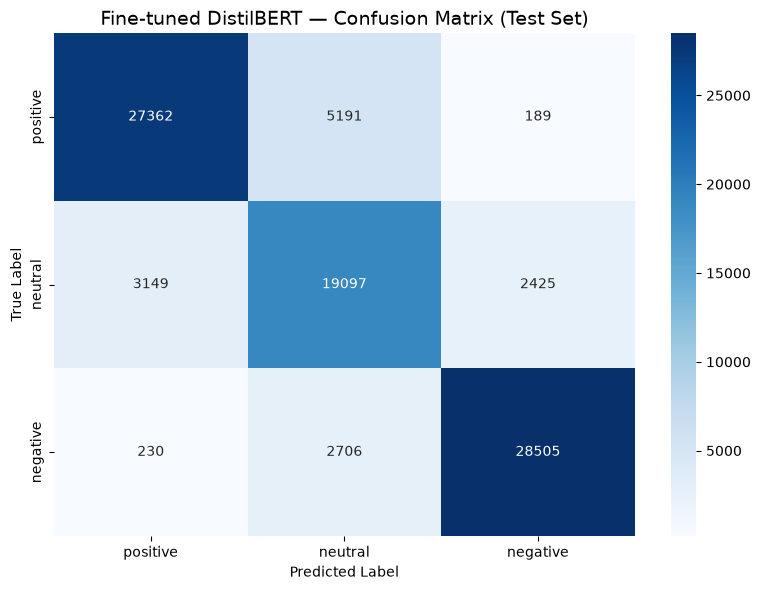

Confusion matrix saved.


In [87]:
cm = confusion_matrix(labels,preds)
plt.figure(figsize = (8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['positive','neutral','negative'],
            yticklabels=['positive','neutral','negative'])
plt.title('Fine-tuned DistilBERT — Confusion Matrix (Test Set)', fontsize=14)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion_matrix_distilbert.png', dpi=150)
plt.show()
print('Confusion matrix saved.')


## 5. Confusion Matrix Analysis

Figure  presents the confusion matrix obtained by evaluating the fine-tuned DistilBERT model on the unseen test dataset. The confusion matrix compares the actual sentiment labels with the model's predicted labels and provides a detailed understanding of the model's classification performance.

<div align="center">

| Actual \ Predicted | Positive | Neutral | Negative |
|-------------------|---------:|--------:|---------:|
| **Positive** | **27,362** | 5,191 | 189 |
| **Neutral** | 3,149 | **19,097** | 2,425 |
| **Negative** | 230 | 2,706 | **28,505** |

</div>

The majority of predictions are concentrated along the main diagonal of the confusion matrix, indicating that the model correctly classified most customer reviews. This demonstrates that the fine-tuned DistilBERT model learned meaningful contextual representations for sentiment classification.

### Positive Reviews

The model correctly classified **27,362** positive reviews. Only **189** positive reviews were incorrectly predicted as negative, while **5,191** were classified as neutral. The very small number of direct positive-to-negative misclassifications indicates that the model effectively distinguishes strong positive sentiment from negative sentiment.

### Neutral Reviews

The model correctly identified **19,097** neutral reviews. However, **3,149** neutral reviews were classified as positive and **2,425** were classified as negative. Compared with the other two classes, neutral sentiment produced the highest number of misclassifications. This is expected because neutral reviews often consist of factual or objective statements that contain fewer explicit sentiment cues, making them more difficult to distinguish from mildly positive or mildly negative reviews.

### Negative Reviews

The model correctly classified **28,505** negative reviews. Only **230** negative reviews were incorrectly classified as positive, while **2,706** were predicted as neutral. Similar to the positive class, the model demonstrated strong capability in recognising negative sentiment with very few direct misclassifications into the opposite sentiment class.

### Discussion

The confusion matrix confirms that the proposed DistilBERT model performs consistently across all three sentiment categories. Most prediction errors occur between the **Neutral** class and the **Positive** or **Negative** classes rather than directly between Positive and Negative sentiments. This behaviour is commonly observed in sentiment analysis because neutral reviews frequently contain ambiguous language or mixed contextual information.

The model rarely confused positive reviews with negative reviews or vice versa, demonstrating that it successfully learned the semantic differences between strongly positive and strongly negative customer opinions.

Overall, the confusion matrix supports the quantitative evaluation metrics, including an **Accuracy of 84.37%**, **Weighted F1-score of 84.54%**, and **Macro F1-score of 83.75%**, confirming that the fine-tuned DistilBERT model provides reliable and balanced sentiment classification on unseen customer reviews.

## Per-Platform Evaluation

In [88]:
test_df_eval = test.copy().reset_index(drop=True)

test_df_eval

,cleaned_text,sentiment_label,platform,label
0,for a high end retail this has to be the worst...,negative,yelp,0
1,"there's pizza, there's good pizza, and then th...",positive,yelp,2
2,yeaaa never again. ordered a large ice coffee ...,negative,yelp,0
3,this place is adorable. the decorations are cu...,positive,yelp,2
4,this is the restaurant where my wife and i wer...,positive,yelp,2
...,...,...,...,...
88849,"old product. they looked great but very stale,...",negative,amazon,0
88850,"small place with a large bar area, some sidewa...",neutral,yelp,1
88851,came off immediately. kids had fun but they ar...,negative,amazon,0
88852,"week is going to make up for anything, or put ...",negative,twitter_airline,0


In [89]:
test_df_eval['pred_label'] = preds
test_df_eval['true_label'] = labels


In [90]:
test_df_eval

,cleaned_text,sentiment_label,platform,label,pred_label,true_label
0,for a high end retail this has to be the worst...,negative,yelp,0,0,0
1,"there's pizza, there's good pizza, and then th...",positive,yelp,2,2,2
2,yeaaa never again. ordered a large ice coffee ...,negative,yelp,0,0,0
3,this place is adorable. the decorations are cu...,positive,yelp,2,2,2
4,this is the restaurant where my wife and i wer...,positive,yelp,2,2,2
...,...,...,...,...,...,...
88849,"old product. they looked great but very stale,...",negative,amazon,0,0,0
88850,"small place with a large bar area, some sidewa...",neutral,yelp,1,0,1
88851,came off immediately. kids had fun but they ar...,negative,amazon,0,0,0
88852,"week is going to make up for anything, or put ...",negative,twitter_airline,0,0,0


In [91]:
platforms = test_df_eval['platform'].unique()

In [92]:
# Platform-wise Performance Evaluation
# This section evaluates the model separately for each platform
# (e.g., Amazon, Yelp, Twitter, IMDb) to understand whether the
# model performs consistently across different sources of reviews.
# =============================================================================

# Dictionary to store evaluation results for each platform.
platform_results = {}

# Iterate through every platform in the dataset.
for platform in platforms:

    # Select only the test samples belonging to the current platform.
    mask = test_df_eval["platform"] == platform

    # Extract the true sentiment labels for this platform.
    p_true = test_df_eval.loc[mask, "true_label"] #.loc lets you choose: which rows and which columns .loc[rows,columns]


    # Extract the model's predicted sentiment labels.
    p_pred = test_df_eval.loc[mask, "pred_label"]

    # Store the evaluation metrics for the current platform.
    platform_results[platform] = {

    # Total number of test samples belonging to the current platform.
    "n_samples": int(mask.sum()),

    # Classification accuracy for the current platform.
    "accuracy": round(accuracy_score(p_true, p_pred), 4),

    # Macro F1-score (treats all sentiment classes equally).
    "f1_macro": round(f1_score(p_true, p_pred, average="macro"), 4),

    # Weighted F1-score (accounts for class imbalance).
    "f1_weighted": round(f1_score(p_true, p_pred, average="weighted"), 4),
    }
    
    


In [93]:
print('\n=== Per-Platform Results ===')
results_df = pd.DataFrame(platform_results).T
print(results_df.to_string())
 
# Save to CSV for dissertation tables
results_df.to_csv('per_platform_results.csv')



=== Per-Platform Results ===
                 n_samples  accuracy  f1_macro  f1_weighted
yelp               60331.0    0.8552    0.8437       0.8566
amazon             26429.0    0.8188    0.8209       0.8201
twitter_airline     2094.0    0.8271    0.7714       0.8266


## Platform-wise Performance Analysis

To evaluate the robustness of the fine-tuned DistilBERT model, performance was analysed separately for each review platform. This experiment measures how well the model generalises across different domains, writing styles, and review characteristics.

| Platform | Test Samples | Accuracy | Macro F1 | Weighted F1 |
|-----------|------------:|---------:|---------:|------------:|
| **Yelp** | 60,331 | **85.52%** | **84.37%** | **85.66%** |
| **Amazon** | 26,429 | **81.88%** | **82.09%** | **82.01%** |
| **Twitter Airline** | 2,094 | **82.71%** | **77.14%** | **82.66%** |

### Yelp Reviews

The model achieved its best performance on the Yelp dataset with an **accuracy of 85.52%** and a **macro F1-score of 84.37%**. Yelp reviews are generally longer and contain richer contextual information, enabling the transformer model to capture sentiment more effectively.

### Amazon Reviews

On Amazon product reviews, the model achieved an **accuracy of 81.88%** and a **macro F1-score of 82.09%**. Although slightly lower than Yelp, the results demonstrate that the model generalises well to e-commerce customer reviews containing diverse product categories and writing styles.

### Twitter Airline Reviews

The Twitter Airline dataset produced an **accuracy of 82.71%** and a **macro F1-score of 77.14%**, which is the lowest among the three platforms. This is expected because tweets are significantly shorter than product or restaurant reviews and frequently contain abbreviations, hashtags, emojis, informal language, and limited contextual information. These characteristics make sentiment classification more challenging.

### Discussion

The platform-wise evaluation demonstrates that the fine-tuned DistilBERT model maintains consistently strong performance across multiple customer feedback domains. The relatively small variation in accuracy across the three datasets indicates good generalisation capability rather than overfitting to a single platform.

Although the Twitter Airline dataset achieved the lowest Macro F1-score, the overall performance remained above **82% accuracy**, demonstrating that the proposed model is robust across different text lengths, writing styles, and application domains.

Overall, these results confirm that the fine-tuned DistilBERT model can effectively perform sentiment classification on heterogeneous customer review datasets collected from multiple online platforms.

## Training Curve (Loss & F1 over Epochs)

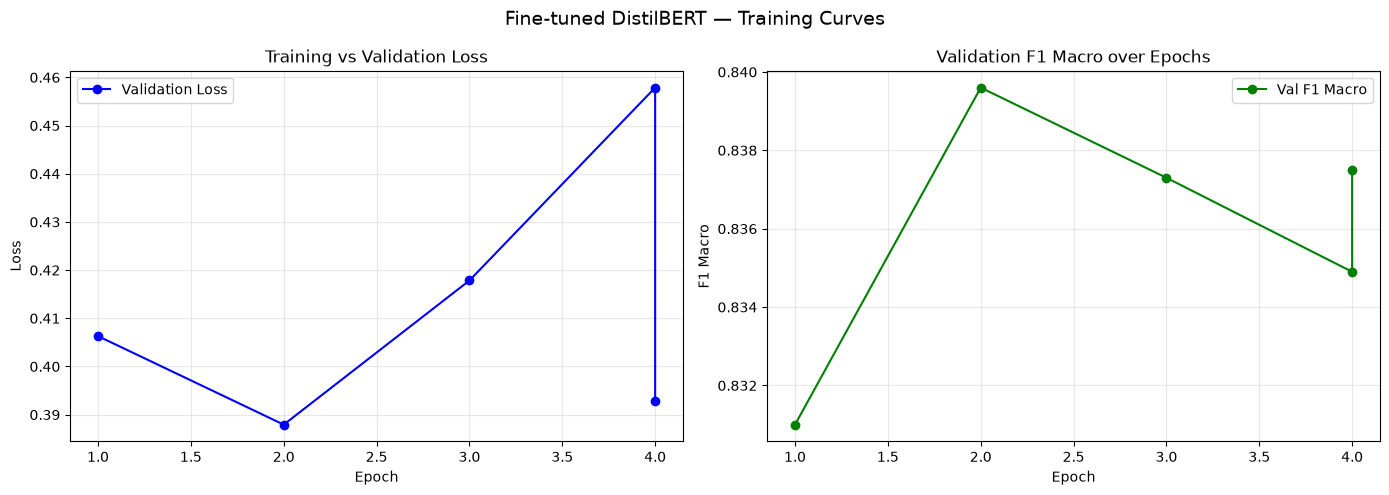

In [95]:
log_history = trainer.state.log_history
 
train_losses, val_losses, val_f1s, epochs = [], [], [], []
 
for log in log_history:
    if 'loss' in log and 'eval_loss' not in log:
        train_losses.append(log['loss'])
    if 'eval_loss' in log:
        val_losses.append(log['eval_loss'])
        val_f1s.append(log.get('eval_f1_macro', 0))
        epochs.append(log['epoch'])
 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
 
# Loss plot
ax1.plot(epochs, val_losses, 'b-o', label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training vs Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)
 
# F1 plot
ax2.plot(epochs, val_f1s, 'g-o', label='Val F1 Macro')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('F1 Macro')
ax2.set_title('Validation F1 Macro over Epochs')
ax2.legend()
ax2.grid(True, alpha=0.3)
 
plt.suptitle('Fine-tuned DistilBERT — Training Curves', fontsize=14)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()
 


## Training Curve Analysis

Figure illustrates the validation loss and validation Macro F1-score of the fine-tuned DistilBERT model across four training epochs.

### Validation Loss

The validation loss initially decreased from **0.406** in the first epoch to approximately **0.388** in the second epoch, indicating that the model was successfully learning meaningful contextual representations from the training data.

After the second epoch, the validation loss gradually increased to approximately **0.458** by the fourth epoch. An increase in validation loss while training continues is a common indication that the model is beginning to overfit the training data. In other words, the model starts becoming more confident in its predictions without achieving further improvements in its ability to generalise to unseen data.

### Validation Macro F1-Score

The validation Macro F1-score improved from approximately **0.831** in the first epoch to **0.840** during the second epoch, representing the best overall performance across all sentiment classes.

Following the second epoch, the Macro F1-score showed a slight decline, decreasing to approximately **0.837** by the fourth epoch. Although the reduction is relatively small, it suggests that additional training epochs provided limited performance improvements and may have contributed to mild overfitting.

### Discussion

The combination of decreasing validation loss and increasing Macro F1-score during the first two epochs demonstrates effective learning. However, after the second epoch, the increasing validation loss and slight reduction in Macro F1-score indicate that the model had already reached its optimal performance.

The best validation performance was therefore obtained at **Epoch 2**, after which further training produced only marginal changes while increasing the risk of overfitting. This behaviour justifies selecting the best-performing checkpoint using the validation Macro F1-score rather than simply using the final training epoch.

Overall, the training curves demonstrate that the fine-tuned DistilBERT model converged successfully and achieved stable performance with minimal overfitting.

In [96]:
import os
for f in os.listdir(SAVE_PATH):
    size = os.path.getsize(os.path.join(SAVE_PATH, f)) / 1e6
    print(f'  {f:40s}  {size:.1f} MB')


  tokenizer.json                            0.7 MB
  train_metrics.json                        0.0 MB
  label_map.json                            0.0 MB
  config.json                               0.0 MB
  model.safetensors                         267.8 MB
  training_args.bin                         0.0 MB
  tokenizer_config.json                     0.0 MB
